In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Vemos los datos

In [2]:
df_datos = pd.read_csv("data/datos_con_probabilidad_impago.csv")
df_datos.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Probabilidad_Impago
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,800.00,2,0,1,0,0,1,0.175035
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,580.00,2,0,0,0,1,0,0.080365
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,130.00,1,0,0,0,0,0,0.102163
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0,0,168.08,1,0,1,0,0,1,0.087424
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,293.94,0,0,1,0,1,0,0.150840


In [3]:
df_amortizacion = pd.read_csv('data/clientes_clasificados_frances_aleman.csv')
df_amortizacion.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [4]:
# Seleccionamos las variables nuevas del dataset de amortización
df_amortizacion = df_amortizacion[
    ['ID', 'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al',
     'Ahorro_Intereses_Al', 'Intereses_Totales_Fr',
     'Sobreesfuerzo_Inicial_Al', 'Sistema_Recomendado',
     'Ambos_Superan_Limite', 'Diferencia_Esfuerzo',
     'Ahorro_Intereses_Pct']
]

# Unimos los dos datasets por ID
df = df_datos.merge(df_amortizacion,on='ID',how='left')

# Comprobamos el resultado
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Probabilidad_Impago,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0.175035,36.439698,44.343385,2940.716995,29095.330653,372.606139,Francés,True,7.903687,10.107178
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0.080365,121.549207,132.165420,550.623822,17003.748822,607.760466,Francés,True,10.616212,3.238250
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0.102163,3.752495,4.380152,132.211310,1891.237810,26.152370,Alemán,False,0.627657,6.990729
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0.087424,5.445751,6.108969,91.132177,1929.482123,34.837147,Alemán,False,0.663217,4.723142
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,0.150840,67.845326,74.854640,210.558419,5390.558419,130.262266,Francés,True,7.009314,3.906059


In [5]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca', 'Personas_Cargo', 'Fiador',
       'Impago', 'Prima', 'Estudios_encoded', 'Estado_Civil_Divorciado',
       'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Probabilidad_Impago',
       'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al', 'Ahorro_Intereses_Al',
       'Intereses_Totales_Fr', 'Sobreesfuerzo_Inicial_Al',
       'Sistema_Recomendado', 'Ambos_Superan_Limite', 'Diferencia_Esfuerzo',
       'Ahorro_Intereses_Pct'],
      dtype='object')

In [6]:
df.isna().sum()

ID                                       0
Edad                                     0
Ingresos                                 0
Monto_Inicial                            0
Scoring_Crediticio                       0
Meses_Empleo                             0
Num_Creditos                             0
Ratio_Interes                            0
Duracion                                 0
Ratio_Deuda_Ingresos                     0
Posesion_Hipoteca                        0
Personas_Cargo                           0
Fiador                                   0
Impago                                   0
Prima                                    0
Estudios_encoded                         0
Estado_Civil_Divorciado                  0
Estado_Civil_Soltero                     0
Tipo_Jornada_Laboral_Desempleado         0
Tipo_Jornada_Laboral_Jornada completa    0
Tipo_Jornada_Laboral_Tiempo parcial      0
Probabilidad_Impago                      0
Esfuerzo_Inicial_Fr                      0
Esfuerzo_In

In [7]:
correlacion_prima = df.corr(numeric_only=True)['Prima'].drop('Prima')

print(
    correlacion_prima.reindex(
        correlacion_prima.abs().sort_values(ascending=False).index
    )
)

Intereses_Totales_Fr                     0.640481
Ratio_Deuda_Ingresos                     0.634848
Diferencia_Esfuerzo                      0.624056
Monto_Inicial                            0.623751
Sobreesfuerzo_Inicial_Al                 0.593188
Ambos_Superan_Limite                     0.525921
Ahorro_Intereses_Al                      0.524219
Esfuerzo_Inicial_Al                      0.389071
Esfuerzo_Inicial_Fr                      0.357788
Ahorro_Intereses_Pct                     0.320555
Duracion                                 0.310915
Ingresos                                 0.210108
Ratio_Interes                            0.137550
Estudios_encoded                         0.126992
Edad                                     0.114118
Estado_Civil_Soltero                    -0.108103
Meses_Empleo                             0.083599
Scoring_Crediticio                      -0.074147
Probabilidad_Impago                     -0.058173
Estado_Civil_Divorciado                  0.036112


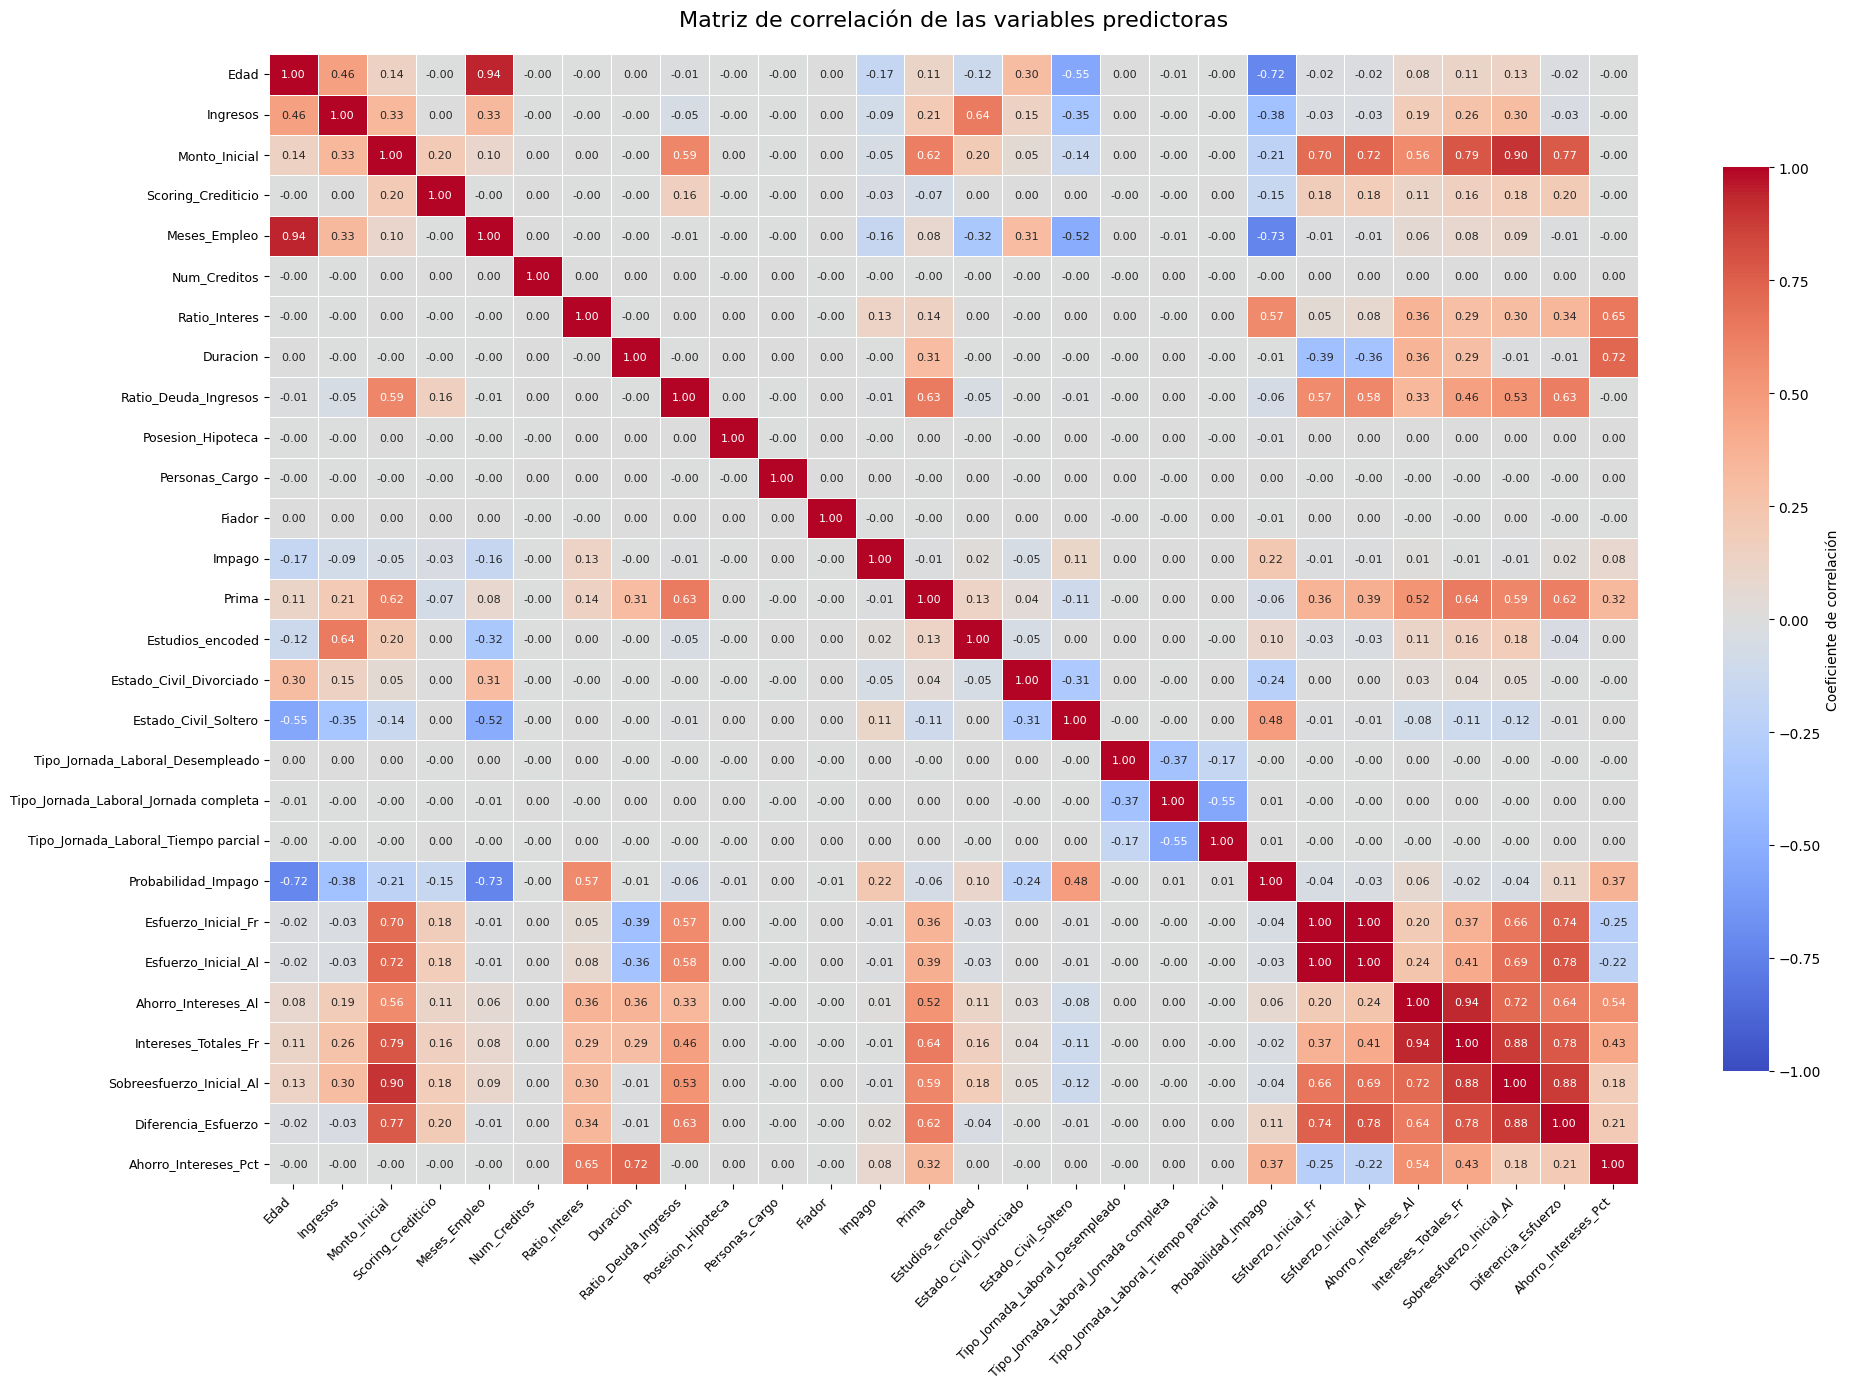

In [8]:
# Matriz de correlación de las variables que realmente entran al modelo
df_num = df.select_dtypes(include=['int64', 'float64'])
correlacion = df_num.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

# Preparamos los datos 

In [9]:
# Seleccionamos las variables predictoras
X = df[['Monto_Inicial',
    'Ratio_Deuda_Ingresos',
    'Scoring_Crediticio',
    'Ingresos',
    'Duracion',
    'Ratio_Interes',
    'Meses_Empleo',
    'Estudios_encoded',
    'Probabilidad_Impago'
]]

# Variable que queremos predecir
y = df['Prima']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, shuffle=True, random_state=42)


Para seleccionar las variables predictoras del modelo, se ha analizado la matriz de correlación para observar la relación entre las distintas variables y la prima. Este análisis permite identificar qué variables pueden aportar información útil y detectar aquellas que tienen una relación muy elevada entre sí.

Se han seleccionado variables relacionadas con las características económicas y financieras del cliente, como el importe inicial del préstamo, los ingresos, el scoring crediticio, la duración del préstamo, el ratio de deuda sobre ingresos y el ratio de interés. También se han incluido los meses de empleo, los estudios y la probabilidad de impago, ya que pueden aportar información relevante para estimar la prima.

Al analizar la matriz de correlación, se ha observado que algunas variables presentan una correlación elevada entre ellas. Por ejemplo, la edad y los meses de empleo tienen una relación bastante alta, ya que normalmente las personas de mayor edad suelen tener más experiencia laboral. Por este motivo, se ha decidido no incluir la edad en el modelo, manteniendo los meses de empleo para evitar utilizar variables que aporten información demasiado similar.

Por otro lado, se han descartado variables como Ahorro_Intereses, Intereses_Totales, Diferencia_Esfuerzo y Sistema_Amortizacion, porque están relacionadas con los cálculos realizados al comparar los sistemas de amortización o con la decisión final sobre cuál utilizar.

En particular, se ha eliminado Sistema_Amortizacion porque el objetivo es predecir la prima antes de decidir qué sistema de amortización se utilizará. También se han descartado las variables relacionadas con el ahorro de intereses y la diferencia de esfuerzo, ya que dependen de cálculos posteriores. De esta forma, se evita utilizar información que no estaría disponible en el momento de realizar la predicción y se reduce el riesgo de fuga de información (data leakage).

Finalmente, se ha decidido trabajar con 9 variables predictoras: Monto_Inicial, Ratio_Deuda_Ingresos, Scoring_Crediticio, Ingresos, Duracion, Ratio_Interes, Meses_Empleo, Estudios_encoded y Probabilidad_Impago. Esta selección se evaluará mediante los resultados del modelo para comprobar si permite mantener una buena capacidad predictiva.

## Probamos un modelo de regresión lineal simple

In [10]:
# Estandarizamos las variables
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [11]:
X_train_scaled = sm.add_constant(X_train_scaled, prepend=True)
modelo_lin_reg = sm.OLS(endog=y_train, exog=X_train_scaled)
modelo_lin_reg = modelo_lin_reg.fit()
print(modelo_lin_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.678
Method:                 Least Squares   F-statistic:                 3.344e+04
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        16:31:52   Log-Likelihood:            -9.2054e+05
No. Observations:              142884   AIC:                         1.841e+06
Df Residuals:                  142874   BIC:                         1.841e+06
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  386.8674 

In [12]:
## Evaluamos el modelo
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

# Añadir la constante al conjunto de test
X_test_scaled = sm.add_constant(X_test_scaled, prepend=True)

# Realizar las predicciones
prediccion_test_scaled = modelo_lin_reg.predict(exog=X_test_scaled)

# Cálculo de métricas de error
mse = mean_squared_error(y_true=y_test, y_pred=prediccion_test_scaled)
rmse = root_mean_squared_error(y_true=y_test, y_pred=prediccion_test_scaled)
mae = mean_absolute_error(y_true=y_test, y_pred=prediccion_test_scaled)
print(f"Primeras cinco predicciones: {prediccion_test_scaled[0:5]}")
print(f"El error (mse) de test es: {round(mse,2)}")
print(f"El error (rmse) de test es: {round(rmse,2)}")
print(f"El error (mae) de test es: {round(mae,2)}")

Primeras cinco predicciones: 78049     606.816317
115875    176.852327
22543     284.299404
119699    380.299129
164399    340.606667
dtype: float64
El error (mse) de test es: 22944.07
El error (rmse) de test es: 151.47
El error (mae) de test es: 120.21


# Comprobamos los supuestos

In [13]:
# Residuos de las predicciones de entrenamiento
prediccion_train_scaled = modelo_lin_reg.predict(exog=X_train_scaled)
residuos_train_scaled = y_train - prediccion_train_scaled # residuos = valores reales - predicciones

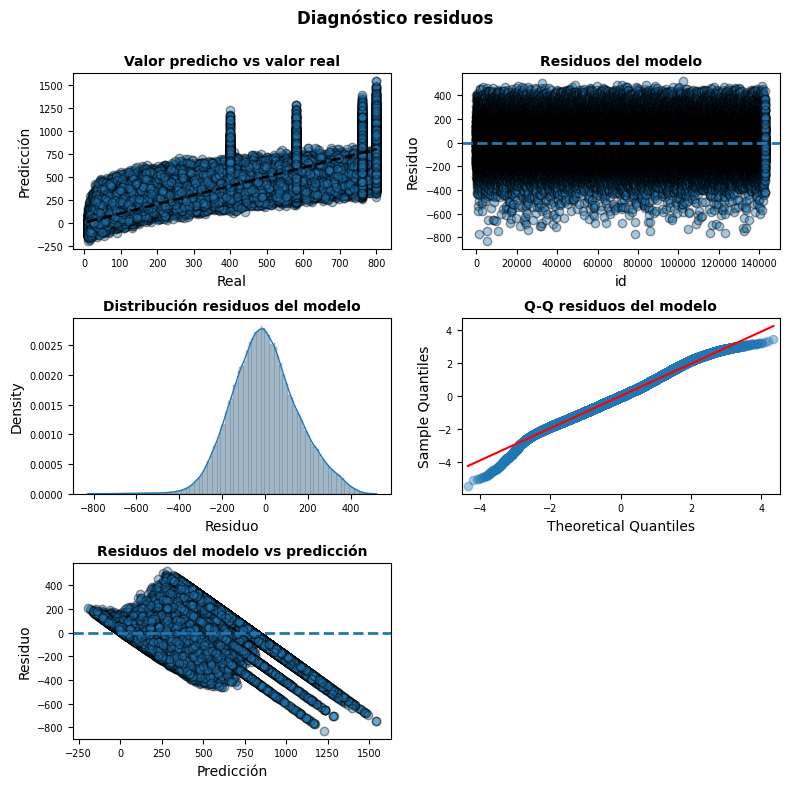

In [14]:
# Gráficos
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8))

axes[0, 0].scatter(y_train, prediccion_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train_scaled,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train_scaled,
    fit   = True, # estandariza los residuos con su ppropia media y desviación típica
    line  = 'q',
    ax    = axes[1, 1], 
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train_scaled, residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2, 1])
fig.tight_layout() # Recoloca automáticamente los gráficos para que títulos y etiquetas no se solapen
plt.subplots_adjust(top=0.9) # Deja libre el 10% superior de la figura para el título general
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

In [15]:
# Prueba de normalidad de Shapiro-Wilk
from scipy import stats
shapiro_test = stats.shapiro(residuos_train_scaled)
shapiro_test

c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 142884.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9965435455963576), pvalue=np.float64(1.4722753190331843e-43))

In [16]:
# Prueba de normalidad de D'Agostino y Pearson

k2, p_value = stats.normaltest(residuos_train_scaled)
print(f"Estadítico= {k2}, p-value = {p_value}")

Estadítico= 406.01633216912484, p-value = 6.833979759188095e-89


Para comprobar si los residuos del modelo siguen una distribución normal, se han aplicado las pruebas de Shapiro-Wilk y D'Agostino-Pearson.

En ambas pruebas, la hipótesis nula establece que los residuos siguen una distribución normal. Los valores p obtenidos son muy inferiores a 0,05 (Shapiro-Wilk: 1,47 · 10⁻⁴³ y D'Agostino-Pearson: 6,83 · 10⁻⁸⁹), por lo que se rechaza esta hipótesis en los dos casos.

Estos resultados indican que existen diferencias estadísticamente significativas respecto a una distribución normal. No obstante, hay que tener en cuenta que el tamaño de la muestra es muy grande, por lo que estas pruebas pueden detectar desviaciones pequeñas de la normalidad. Los estadísticos del propio modelo lineal (asimetría 0,11 y curtosis 3,14) indican que la distribución de los residuos se aleja poco de la normal.

Por otro lado, el modelo lineal explica el 67,8 % de la varianza de la prima (R² = 0,678) y obtiene un RMSE de test de 151,47 y un MAE de 120,21. Estos errores se reducen mucho al aumentar el grado del polinomio (ver más abajo), lo que apunta a una relación no lineal entre las variables y la prima.

## Pruebas de modelado con diferentes grados polinómicos

In [17]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

# Particiones de validación cruzada: las mismas para todos los modelos
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [18]:
def preparar(X_tr, X_val, grado):
    # Crea el polinomio y estandariza. Se ajusta solo con los datos de entrenamiento (fit)
    # y se aplica a los de validación (transform), para no usar información de validación
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    A = poly.fit_transform(X_tr)
    B = poly.transform(X_val)
    scaler = StandardScaler()
    A = scaler.fit_transform(A)
    B = scaler.transform(B)
    return A, B

In [19]:
def rmse_cv(modelo, grado, X, y):
    # Devuelve el RMSE medio de validación cruzada y su desviación entre folds
    errores = [] # lista donde se guardará el error de cada fold
    for idx_train, idx_val in cv.split(X): 
        # cv es el objeto de validación cruzada definido fuera de la función (global). Su método split devuelve en cada vuelta los índices de las filas que van a entrenamiento y a validación. Se repite una vez por fold.
        A, B = preparar(X.iloc[idx_train], X.iloc[idx_val], grado)   # preparamos los datos de este fold
        modelo.fit(A, y.iloc[idx_train])                              # entrenamos con el fold de entrenamiento
        pred = modelo.predict(B)                                      # predecimos el fold de validación
        errores.append(root_mean_squared_error(y.iloc[idx_val], pred))
    return np.mean(errores), np.std(errores)
    # Devuelve dos números: el RMSE medio entre folds (qué tan bien rinde el modelo) y su desviación típica (qué tan estable es entre folds)

In [20]:
# Probamos los grados 1 a 4 y guardamos el error de cada uno
resultados = []
for grado in [1, 2, 3, 4]:
    media, desviacion = rmse_cv(LinearRegression(), grado, X_train, y_train)
    resultados.append({"grado": grado, "RMSE_cv": media, "desviacion_cv": desviacion})

resultados_cv = pd.DataFrame(resultados)
print(resultados_cv.round(2))

   grado  RMSE_cv  desviacion_cv
0      1   151.98           0.70
1      2    97.58           0.37
2      3    75.18           0.24
3      4    64.38           0.21


La validación cruzada muestra que el RMSE disminuye al aumentar el grado: 151,98 (grado 1), 97,58 (grado 2), 75,18 (grado 3) y 64,38 (grado 4), con desviaciones entre folds pequeñas (entre 0,70 y 0,21), lo que indica que los resultados son estables. El grado 4 es el que menor error obtiene de los probados, por lo que se evalúa con él. La mejora de grado 3 a 4 sigue siendo notable (unos 10,8 puntos de RMSE), así que no se descarta que grados superiores mejoren aún más, aunque a costa de un número de términos muy elevado (714 con 9 variables en grado 4). 

## Evaluamos el modelo con grado 4

In [21]:
# Preparamos los datos de grado 3 (polinomio y estandarización ajustados con train)
A_train, A_test = preparar(X_train, X_test, 4)

# Entrenamos con todo el train
modelo_grado4 = LinearRegression()
modelo_grado4.fit(A_train, y_train)

# Predicciones y métricas en train y test
pred_train = modelo_grado4.predict(A_train)
pred_test = modelo_grado4.predict(A_test)
print(f"Train: RMSE = {root_mean_squared_error(y_train, pred_train):.2f} | MAE = {mean_absolute_error(y_train, pred_train):.2f} | R² = {r2_score(y_train, pred_train):.3f}")
print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | MAE = {mean_absolute_error(y_test, pred_test):.2f} | R² = {r2_score(y_test, pred_test):.3f}")

Train: RMSE = 63.85 | MAE = 46.90 | R² = 0.943
Test:  RMSE = 63.43 | MAE = 46.75 | R² = 0.944


En grado 4, las métricas de train y test son casi idénticas (RMSE de 63,85 frente a 63,43; MAE de 46,90 frente a 46,75; R² de 0,943 frente a 0,944), por lo que no se observa sobreajuste y el modelo generaliza bien. Frente al modelo lineal (RMSE de test de 151,47), el error se reduce a menos de la mitad.


## Curvas de aprendizaje comparativa entre grados

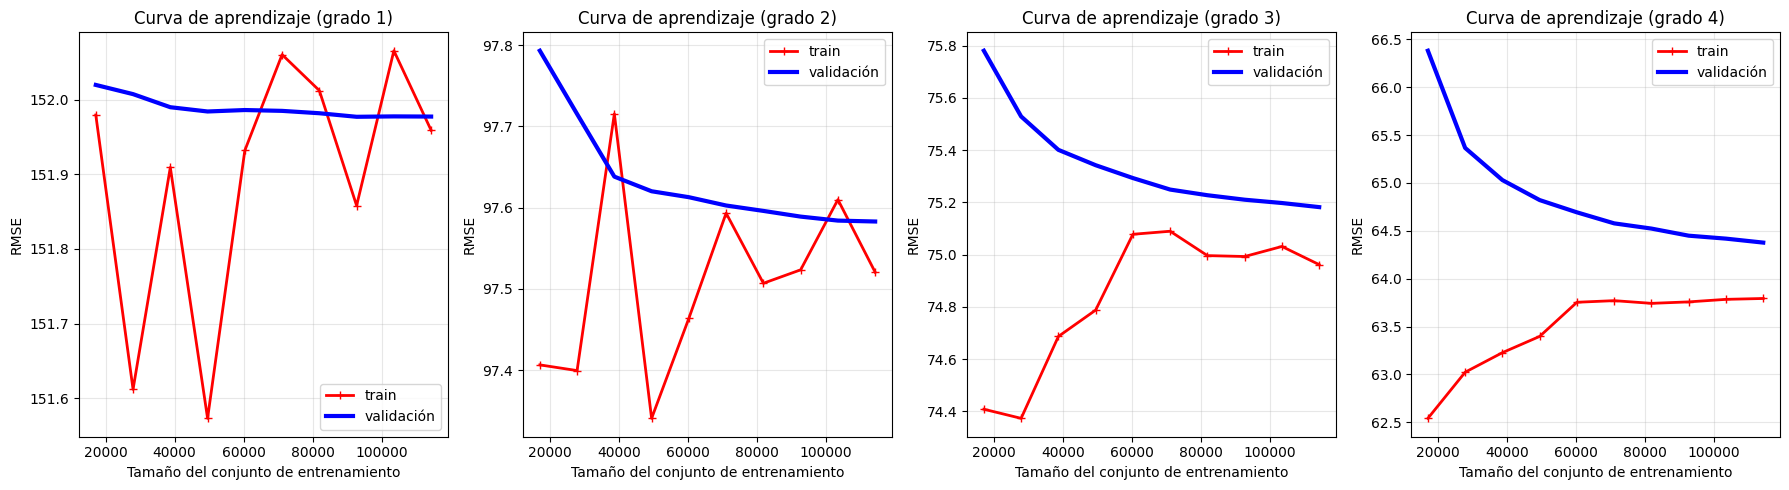

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import learning_curve

def curva_aprendizaje(X, y, grado, ax):
    """Dibuja la curva de aprendizaje de una regresión polinómica."""

    # Preparamos los pasos que seguirá el modelo
    modelo = Pipeline([
        ("polinomio", PolynomialFeatures(degree=grado, include_bias=False)),
        ("escalado", StandardScaler()),
        ("regresion", LinearRegression())
    ])

    # Calculamos los errores con distintos tamaños de entrenamiento
    train_sizes, train_scores, valid_scores = learning_curve(
        modelo,
        X,
        y,
        train_sizes=np.linspace(0.15, 1.0, 10),
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    # Cambiamos el signo para obtener errores positivos
    train_errors = -train_scores.mean(axis=1)
    valid_errors = -valid_scores.mean(axis=1)

    # Dibujamos las curvas
    ax.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
    ax.plot(train_sizes, valid_errors, "b-", linewidth=3, label="validación")

    ax.set_xlabel("Tamaño del conjunto de entrenamiento")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Curva de aprendizaje (grado {grado})")
    ax.legend()
    ax.grid(True, alpha=0.3)


# Dibujamos las curvas para los tres grados
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, grado in zip(axes, [1, 2, 3,4]):
    curva_aprendizaje(X_train, y_train, grado, ax)

plt.tight_layout()
plt.show()

Las curvas de aprendizaje muestran cómo cambia el RMSE de entrenamiento y de validación al aumentar el tamaño del conjunto de entrenamiento, para cada grado del polinomio.

En el grado 1 las dos curvas están prácticamente planas y juntas, en torno a 152. Las oscilaciones de la curva de train son muy pequeñas (menos de 0,5 de RMSE) y se deben al ruido de cada partición. Como el error es alto en train y en validación, el modelo es demasiado simple para captar la relación entre las variables y la prima (infraajuste), y tener más datos no lo mejoraría.

En el grado 2 el comportamiento es parecido: las curvas convergen en torno a 97,5-97,6 y apenas se separan. El error sigue siendo alto en ambas, así que continúa el infraajuste, aunque es claramente menor que con el grado 1.

En el grado 3 la curva de validación baja hasta 75,2 y la de train sube hasta 75,0, con una diferencia final de unos 0,2 puntos. Ambas se estabilizan, de modo que no hay sobreajuste, pero el error sigue siendo elevado.

En el grado 4 el error baja de nuevo: la validación desciende de 66,4 a 64,4 y el train sube de 62,5 a 63,8. La diferencia final entre ambas es de unos 0,6 puntos, es decir, pequeña, y las dos curvas se aplanan al final. Esto indica que el modelo no sobreajusta y que, añadir más datos aportaría muy poca mejora.

En conjunto, la mejora entre grados se debe a que el modelo gana capacidad (menor sesgo), y no a un problema de varianza o de falta de datos. Esto respalda la elección del grado 4 como el de menor error entre los probados.

# Pruebas de regularización

In [23]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from scipy.stats import loguniform

# Datos de grado 4: creamos el polinomio y estandarizamos con todo el train
# Datos de grado 4
poly = PolynomialFeatures(degree=4, include_bias=False)

# Creamos las variables polinómicas
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Estandarizamos las variables polinómicas
scaler = StandardScaler()
X_train_poly = scaler.fit_transform(X_train_poly)
X_test_poly = scaler.transform(X_test_poly)

## 1. Lasso

In [24]:
# Búsqueda de Lasso
random_lasso = RandomizedSearchCV(
    estimator=Lasso(max_iter=1000),
    param_distributions={"alpha": loguniform(0.001, 10)},
    n_iter=3,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42
)

In [25]:
random_lasso.fit(X_train_poly, y_train)

c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.606e+08, tolerance: 8.193e+05
  model = cd_fast.enet_coordinate_descent(
c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.585e+08, tolerance: 8.211e+05
  model = cd_fast.enet_coordinate_descent(
c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the 

,estimator,Lasso()
,param_distributions,{'alpha': <scipy.stats....001945ACAFD90>}
,n_iter,3
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [26]:
print("Lasso")
print("Mejores parámetros:", random_lasso.best_params_)
print("RMSE cv:", round(-random_lasso.best_score_, 2))

Lasso
Mejores parámetros: {'alpha': np.float64(0.03148911647956861)}
RMSE cv: 74.83


## 2.Ridge

In [27]:
# Rango de alpha de cada modelo. Usamos RMSE para poder compararlos con los grados
random_ridge = RandomizedSearchCV(
    estimator=Ridge(),
    param_distributions={"alpha": loguniform(0.0001, 1000)},
    n_iter=3,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42
)

In [28]:
random_ridge.fit(X_train_poly, y_train)

,estimator,Ridge()
,param_distributions,{'alpha': <scipy.stats....001945C2020D0>}
,n_iter,3
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [29]:
print("Ridge")
print("Mejores parámetros:", random_ridge.best_params_)
print("RMSE cv:", round(-random_ridge.best_score_, 2))

Ridge
Mejores parámetros: {'alpha': np.float64(0.041858227295469716)}
RMSE cv: 65.44


## 3. ElasticNet

In [30]:
# Búsqueda de ElasticNet
random_elastic = RandomizedSearchCV(
    estimator=ElasticNet(max_iter=1000),
    param_distributions={
        "alpha": loguniform(0.001, 1000),
        "l1_ratio": [0.1, 0.5, 0.75, 0.9, 1.0]
    },
    n_iter=3,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
)

In [31]:
random_elastic.fit(X_train_poly, y_train)

c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.448e+08, tolerance: 8.193e+05
  model = cd_fast.enet_coordinate_descent(
c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.536e+08, tolerance: 8.211e+05
  model = cd_fast.enet_coordinate_descent(
c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the 

,estimator,ElasticNet()
,param_distributions,"{'alpha': <scipy.stats....00194569CEC40>, 'l1_ratio': [0.1, 0.5, ...]}"
,n_iter,3
,scoring,'neg_root_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [32]:
print("ElasticNet")
print("Mejores parámetros:", random_elastic.best_params_)
print("RMSE cv:", round(-random_elastic.best_score_, 2))

ElasticNet
Mejores parámetros: {'alpha': np.float64(0.012606912518374074), 'l1_ratio': 1.0}
RMSE cv: 74.29


## 4. Sin regularizar

In [33]:
sin_reg = cross_val_score(
    LinearRegression(),
    X_train_poly,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
)


print("Sin regularizar (grado 4), RMSE cv:", round(-sin_reg.mean(), 2))

Sin regularizar (grado 4), RMSE cv: 64.4


Al comparar los modelos mediante el RMSE de validación cruzada, la regresión polinómica de grado 4 sin regularizar obtiene el menor error (64,40), seguida de cerca por Ridge (65,44). Es decir, aplicar regularización Ridge no supone ninguna mejora; el error es incluso algo mayor (aproximadamente un punto).

Por otro lado, Lasso y ElasticNet presentan errores más elevados, con RMSE de 74,83 y 74,29 respectivamente (en ElasticNet el mejor l1_ratio fue 1,0, por lo que equivale a Lasso). Además, ambos mostraron avisos de no convergencia con la configuración probada (max_iter = 1000), por lo que estos valores deben tomarse con cautela. Hay que tener en cuenta también que la búsqueda de hiperparámetros se limitó a 3 combinaciones por modelo. En cualquier caso, ninguno mejora al modelo sin regularizar.

Por tanto, siguiendo el principio de parsimonia, se elige la regresión polinómica de grado 4 sin regularizar, ya que ofrece un rendimiento igual o mejor que el de Ridge sin necesidad de añadir regularización.

# Modelo final

In [34]:
# Entrenamos el modelo final sin regularizar (grado 4)
modelo_final = LinearRegression()
modelo_final.fit(X_train_poly, y_train)

print("Modelo final: Regresión polinómica de grado 4 sin regularizar")

# Predicciones en train y test
pred_train = modelo_final.predict(X_train_poly)
pred_test = modelo_final.predict(X_test_poly)

# Métricas en train y test
print(f"Train: RMSE = {root_mean_squared_error(y_train, pred_train):.2f} | MAE = {mean_absolute_error(y_train, pred_train):.2f} | R² = {r2_score(y_train, pred_train):.3f}")
print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | MAE = {mean_absolute_error(y_test, pred_test):.2f} | R² = {r2_score(y_test, pred_test):.3f}")

Modelo final: Regresión polinómica de grado 4 sin regularizar
Train: RMSE = 63.85 | MAE = 46.90 | R² = 0.943
Test:  RMSE = 63.43 | MAE = 46.75 | R² = 0.944


## Descenso de gradiente

In [44]:
from sklearn.linear_model import SGDRegressor # Cargamos la clase SGDRegressor, que implementa el descenso de gradiente estocástico para regresión lineal y regularización L1/L2.

sgd = SGDRegressor(
    loss="squared_error",       # error cuadrático
    penalty=None,               # penalización ninguna
    learning_rate="adaptive",  # Disminuye eta0 solo cuando la pérdida se estanca
    eta0=0.00001,                  # tasa de aprendizaje inicial
    max_iter=100000,            # número máximo de iteraciones, significa que si no se alcanza la convergencia antes de max_iter, se detiene el entrenamiento
    tol=1e-6,                 # mejora mínima de la pérdida para considerar que el modelo sigue avanzando   
    n_iter_no_change=100,       # iteraciones seguidas sin mejora (> tol) antes de parar (o de reducir el paso, si es "adaptive")
    random_state=42,
)
sgd.fit(X_train_poly, y_train)

b_sgd = sgd.intercept_[0]   # intercepto 
w_sgd = sgd.coef_           # pesos

print(f"MSE test: {round(mean_squared_error(y_test, sgd.predict(X_test_poly)), 2)}")
print(f"RMSE test: {round(root_mean_squared_error(y_test, sgd.predict(X_test_poly)), 2)}")
print(f"MAE test: {round(mean_absolute_error(y_test, sgd.predict(X_test_poly)), 2)}")

MSE test: 4683.95
RMSE test: 68.44
MAE test: 50.96


In [45]:
# Comparamos los coeficientes del SGDRegressor con los de scikit-learn (modelo_final)
nombres = poly.get_feature_names_out()

comparacion = pd.DataFrame({
    "SGDRegressor": np.r_[b_sgd, w_sgd],
    "sklearn": np.r_[modelo_final.intercept_, modelo_final.coef_]},
    index=["intercepto", *nombres])
comparacion["diferencia"] = (comparacion["SGDRegressor"] - comparacion["sklearn"]).abs()
print(comparacion.round(2))

# RMSE en test con el SGDRegressor
pred_sgd = sgd.predict(X_test_poly)
print("RMSE test (SGDRegressor):", round(root_mean_squared_error(y_test, pred_sgd), 2))
print("RMSE test (sklearn):     ", round(root_mean_squared_error(y_test, pred_test), 2))

                                          SGDRegressor  sklearn  diferencia
intercepto                                      386.87   386.87        0.00
Monto_Inicial                                   277.95 -1512.79     1790.73
Ratio_Deuda_Ingresos                            -37.57   124.48      162.05
Scoring_Crediticio                               73.34 -9743.43     9816.77
Ingresos                                        -31.19   -73.11       41.91
...                                                ...      ...         ...
Estudios_encoded^4                               -6.07   -32.01       25.94
Estudios_encoded^3 Probabilidad_Impago           26.23    66.07       39.83
Estudios_encoded^2 Probabilidad_Impago^2          2.38   275.11      272.73
Estudios_encoded Probabilidad_Impago^3           -3.32   566.43      569.75
Probabilidad_Impago^4                            -6.74   -55.86       49.12

[715 rows x 3 columns]
RMSE test (SGDRegressor): 68.44
RMSE test (sklearn):      63.43


# INTERPRETACION DE LOS RESULTADOS

El descenso de gradiente estocástico (SGDRegressor), con una tasa de aprendizaje de 0,00001, obtiene un RMSE de test de 68,44 (MAE de 50,96), algo superior al del modelo de sklearn sin regularizar (63,43). Por tanto, el SGD converge, pero no llega al mínimo que encuentra la solución de sklearn. El intercepto coincide (386,87), pero los coeficientes presentan diferencias importantes en algunas variables, como Monto_Inicial (277,95 frente a −1512,79), Ratio_Deuda_Ingresos (−37,57 frente a 124,48), Scoring_Crediticio (73,34 frente a −9743,43) e Ingresos (−31,19 frente a −73,11). Esto se debe a que los términos polinómicos están muy correlacionados entre sí, por lo que existen muchas combinaciones de coeficientes con un error parecido, y a que el SGD se detiene antes de alcanzar la solución exacta. Por eso, nos quedamos con el modelo de sklearn (regresión polinómica de grado 4 sin regularizar) como modelo final, ya que obtiene mejores resultados en test.

## Coeficientes del modelo final


In [37]:
# Mostramos el intercepto
print("Intercepto:", modelo_final.intercept_)

nombres = poly.get_feature_names_out(X_train.columns)

coeficientes = pd.Series(modelo_final.coef_, index=nombres)

print(coeficientes)

Intercepto: 386.8673678209166
Monto_Inicial                              -1512.787017
Ratio_Deuda_Ingresos                         124.475206
Scoring_Crediticio                         -9743.429619
Ingresos                                     -73.108449
Duracion                                    -917.031696
                                               ...     
Estudios_encoded^4                           -32.006762
Estudios_encoded^3 Probabilidad_Impago        66.065627
Estudios_encoded^2 Probabilidad_Impago^2     275.113338
Estudios_encoded Probabilidad_Impago^3       566.428586
Probabilidad_Impago^4                        -55.862588
Length: 714, dtype: float64


## Primas

In [48]:
# Creamos las variables polinómicas de todos los clientes
X_poly = poly.transform(X)

# Estandarizamos las variables polinómicas
X_poly = scaler.transform(X_poly)

# Calculamos la prima estimada con el modelo final
primas_estimadas = modelo_final.predict(X_poly)

# Creamos un DataFrame con los resultados
df_primas = df.copy()
df_primas['Prima_Estimada'] = primas_estimadas

# Calculamos la diferencia entre la prima real y la estimada
df_primas["diferencia"] = df_primas["Prima"] - df_primas["Prima_Estimada"]

# Mostramos los resultados
df_primas[['ID', 'Prima', 'Prima_Estimada', 'diferencia', "Impago", "Probabilidad_Impago"]]

,ID,Prima,Prima_Estimada,diferencia,Impago,Probabilidad_Impago
0,KG9CT9,800.00,803.986258,-3.986258,0,0.175035
1,V5O0K9,580.00,803.691423,-223.691423,0,0.080365
2,YE5GD0,130.00,125.402535,4.597465,0,0.102163
3,Q6HQ3D,168.08,145.129599,22.950401,0,0.087424
4,XO8CO4,293.94,348.091339,-54.151339,0,0.150840
...,...,...,...,...,...,...
178601,VLZOS9,760.00,774.034142,-14.034142,0,0.098238
178602,Z0BY9Y,542.47,602.091565,-59.621565,1,0.072577
178603,ARBQ2V,188.19,144.846551,43.343449,0,0.072289
178604,1LVUEW,58.46,85.123062,-26.663062,0,0.095739


# Interpretación de los resultados

**Modelo elegido:** regresión polinómica de grado 4 sin regularizar, aplicada a las 9 variables predictoras seleccionadas, para predecir la prima del seguro. Se eligió tras comparar los grados 1 a 4 mediante validación cruzada y probar Ridge, Lasso y ElasticNet, sin que la regularización mejorara el resultado. Obtuvo un RMSE de validación cruzada de 64,40 (Ridge: 65,44). En el conjunto de test obtuvo un RMSE de 63,43, un MAE de 46,75 y un R² de 0,944 (en train: RMSE de 63,85, MAE de 46,90 y R² de 0,943), por lo que no hay señales de sobreajuste.

**Fórmula:**

Prima = 386,87 + Σ βⱼ · (φⱼ − μⱼ) / σⱼ

donde φⱼ son las variables originales y sus términos polinómicos de grado 2, 3 y 4 (por ejemplo, Monto_Inicial², Monto_Inicial × Duracion o Scoring_Crediticio³ × Ratio_Interes), μⱼ y σⱼ son la media y la desviación típica de cada término en el conjunto de entrenamiento y los βⱼ son los coeficientes estimados por mínimos cuadrados (714 en total). El valor 386,87 es el intercepto del modelo, que coincide con la prima media del conjunto de entrenamiento al estar los términos estandarizados.

Entre los coeficientes de los términos de primer grado se encuentran Scoring_Crediticio (−9743,43), Monto_Inicial (−1512,79), Duracion (−917,03), Ratio_Deuda_Ingresos (124,48) e Ingresos (−73,11). Estos valores corresponden a términos concretos del polinomio, no a variables individuales. Al estar los términos polinómicos muy correlacionados entre sí, los coeficientes no pueden interpretarse por separado (por ejemplo, Monto_Inicial tiene signo positivo en el modelo lineal y negativo en su término de primer grado aquí).

**Cómo se lee:** El modelo utiliza las características económicas y financieras de cada cliente (importe inicial, ratio de deuda sobre ingresos, scoring crediticio, ingresos, duración, ratio de interés, meses de empleo, estudios y probabilidad de impago), junto con sus combinaciones polinómicas hasta grado 4, para estimar la prima del seguro. No se aplica regularización porque ni Ridge (que reduce el tamaño de los coeficientes sin anularlos) ni Lasso y ElasticNet (que pueden dejarlos exactamente en cero) mejoraron el error de validación cruzada del modelo sin regularizar.